Assignment 4 : Develop and LSTM-based model for time-series forecasting using stock-price weather or sales datasets.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Generate monthly sales data
np.random.seed(42)

months = pd.date_range(start="2015-01-01", periods=120, freq="MS")

trend = np.linspace(100, 300, 120)
seasonality = 30 * np.sin(2 * np.pi * np.arange(120) / 12)
noise = np.random.normal(0, 10, 120)

sales = trend + seasonality + noise

df = pd.DataFrame({
    "Date": months,
    "Sales": sales
})

print(df.head())
print("\nDataset shape:", df.shape)

        Date       Sales
0 2015-01-01  104.967142
1 2015-02-01  115.298029
2 2015-03-01  135.818992
3 2015-04-01  150.272315
4 2015-05-01  130.361917

Dataset shape: (120, 2)


In [ ]:
# Normalize sales data
scaler = MinMaxScaler(feature_range=(0, 1))

sales_values = df[["Sales"]].values

# Split data into training and testing sets (80:20)
split = int(len(sales_values) * 0.8)

train_data = sales_values[:split]
test_data = sales_values[split:]

# Fit scaler only on training data
train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

# Create sequences
def create_sequences(data, lookback=12):
    X, y = [], []

    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

# Training sequences
X_train, y_train = create_sequences(train_scaled)

# Testing sequences (include previous training observations)
combined_data = np.concatenate(
    (train_scaled[-12:], test_scaled), axis=0
)

X_test, y_test = create_sequences(combined_data)

# Reshape for LSTM input: samples, timesteps, features
X_train = X_train.reshape(X_train.shape[0], 12, 1)
X_test = X_test.reshape(X_test.shape[0], 12, 1)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (84, 12, 1)
X_test shape: (24, 12, 1)
y_train shape: (84,)
y_test shape: (24,)


In [ ]:
# Build LSTM model
model = Sequential([
    LSTM(50, activation="tanh", input_shape=(12, 1)),
    Dropout(0.2),
    Dense(1)
])

# Compile model
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Display model architecture
model.summary()

# Train model
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - loss: 0.1601 - val_loss: 0.1716
Epoch 2/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0509 - val_loss: 0.0275
Epoch 3/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0215 - val_loss: 0.0491
Epoch 4/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0367 - val_loss: 0.0407
Epoch 5/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0237 - val_loss: 0.0179
Epoch 6/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0174 - val_loss: 0.0259
Epoch 7/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0184 - val_loss: 0.0263
Epoch 8/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0202 - val_loss: 0.0196
Epoch 9/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0186 - val_loss: 0.0177
Epoch 10/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0162 - val_loss: 0.0200
Epoch 11/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0182 - val_loss: 0.0183
Epoch 12/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0189 - val_loss: 0.0174
E

In [ ]:
# Generate predictions
y_pred = model.predict(X_test)

# Convert values back to original sales scale
y_pred_actual = scaler.inverse_transform(y_pred)
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
mape = np.mean(
    np.abs((y_test_actual - y_pred_actual) / y_test_actual)
) * 100

print("Model Evaluation:")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step
Model Evaluation:
MAE: 22.02
RMSE: 26.65
MAPE: 7.62%


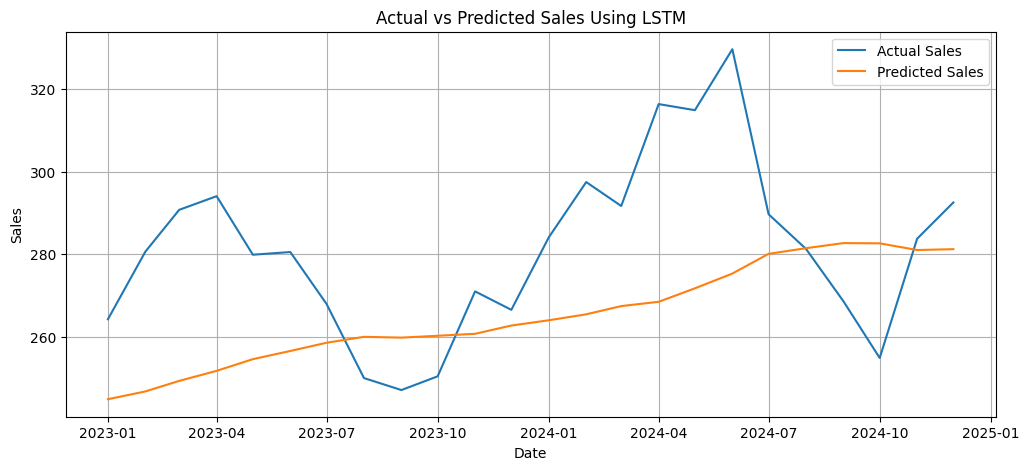

In [ ]:
# Plot actual and predicted sales
plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"].iloc[split:],
    y_test_actual.flatten(),
    label="Actual Sales"
)

plt.plot(
    df["Date"].iloc[split:],
    y_pred_actual.flatten(),
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales Using LSTM")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

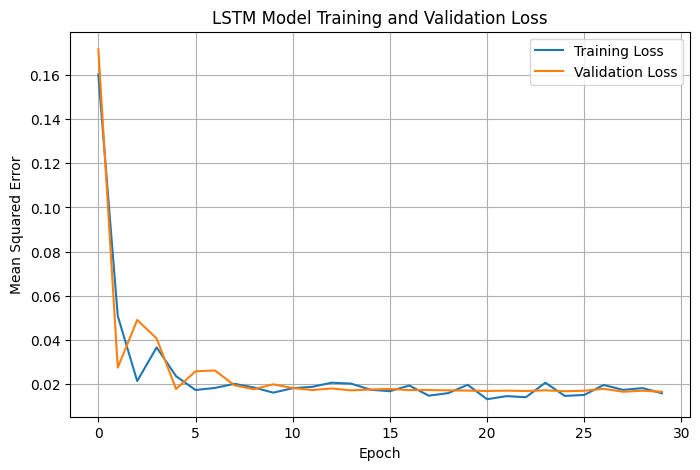

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Model Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.show()